## 1. The task

Every graph in PROTEINS is one protein (Borgwardt et al., 2005). A node is a **secondary-structure element** (SSE) of the protein: a helix, a sheet or a turn. Two SSEs are joined if they are neighbours along the amino-acid chain or close together in 3D space. We predict one label $y\in\{0,1\}$ for the whole protein: $y=0$ is an **enzyme** and $y=1$ a **non-enzyme**. (The raw files store 663 graphs with label 1 and 450 with label 2; PROTEINS has 663 enzymes and 450 non-enzymes, and PyG maps the raw labels 1, 2 to 0, 1.) This is graph classification.

The model is the **enhanced classic GNN** of Lecture 17 and Luo, Shi and Wu (ICML 2025), *Can Classic GNNs Be Strong Baselines for Graph-level Tasks?*: a GIN layer wrapped in normalization, dropout, residual connections, a feed-forward network and positional encodings. We call it **GIN⁺**. The readout, the step that turns the node embeddings into one graph vector, is tuned like any other hyperparameter: flat sum, mean and max, a **type-aware** readout that pools helices, sheets and turns separately, and the hierarchical poolers **SAGPool**, **DiffPool** and **MinCutPool**.

The notebook follows the UPFD notebook of the same model step by step, so the two datasets can be compared trick by trick. It first tunes GIN⁺ on the validation split (Milestone 2) and then runs the same analyses: ablations, readouts, depth, dropout, t-SNE, efficiency, robustness, errors by graph shape and explainability.

Kaggle already has PyTorch, so we only install PyTorch Geometric.

In [1]:
!pip install -q torch_geometric

## 2. Set the experiment budget

All the settings that control run time are here.

A training run lasts at most `epochs` epochs and stops early once validation accuracy has not improved for `patience` epochs. The search tries `n_trials` random configurations, each with every seed in `search_seeds`. The winner is retrained on ten fresh seeds, `final_seeds`; the ablations use the first five, `abl_seeds`, and the depth and dropout sweeps the first three, `sweep_seeds`.

In [2]:
import time
t0 = time.time()
epochs, patience, batch_size = 200, 30, 64
n_trials, search_seeds = 30, [0, 1, 2]
final_seeds = list(range(100, 110))
abl_seeds, sweep_seeds = final_seeds[:5], final_seeds[:3]

## 3. Load PROTEINS

PROTEINS is one of the TU Dortmund benchmark datasets, and PyG downloads it with `TUDataset`. By default `TUDataset` keeps only the SSE type; `use_node_attr=True` also keeps the one continuous node attribute, the length of the SSE in amino acids. Each node then has 4 numbers: the length, followed by a one-hot code for helix, sheet or turn.

The data goes to `/tmp` so that Kaggle does not copy the raw files into the output. PyG warns on every max-pooling call that an optional package would make it faster; we silence that message.

In [3]:
import torch
import warnings
from torch_geometric.datasets import TUDataset
warnings.filterwarnings('ignore', message='.*can be accelerated via')

dataset = TUDataset('/tmp/tud', 'PROTEINS', use_node_attr=True)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("graphs =", len(dataset), "   node features =", dataset.num_features, "   device =", device)
print("first nodes of the first protein:\n", dataset[0].x[:4])

graphs = 1113    node features = 4    device = cuda
first nodes of the first protein:
 tensor([[23.,  1.,  0.,  0.],
        [10.,  1.,  0.,  0.],
        [25.,  1.,  0.,  0.],
        [ 7.,  1.,  0.,  0.]])


## 4. What a protein graph looks like

Before modelling we check the facts the notebook relies on: the edges are stored in both directions, the graph sizes, how common each SSE type is, and the range of the length attribute. The raw files store the SSE type only as 0, 1 or 2. The lengths identify them: type 0 has a median length of 9 amino acids (an $\alpha$-helix), type 1 a median of 5 (a $\beta$-strand of a sheet), and type 2 is rare and short, at most 25 (a turn). Unlike a retweet cascade, a protein graph contains **cycles**: SSEs that are close in space close loops in the chain.

In [4]:
X = torch.cat([g.x for g in dataset])
sizes = torch.tensor([g.num_nodes for g in dataset]).float()
print("undirected graphs:", sum(g.is_undirected() for g in dataset), "of", len(dataset))
print("nodes per graph: mean =", round(sizes.mean().item(), 1), "  median =", sizes.median().item(), "  max =", int(sizes.max()))
print("edges per graph: mean =", round(sum(g.num_edges for g in dataset) / 2 / len(dataset), 1))
print("SSE types (helix, sheet, turn):", X[:, 1:].sum(0).long().tolist())
print("median length per type:", [X[X[:, 1 + t] == 1, 0].median().item() for t in range(3)])
print("length attribute: min =", X[:, 0].min().item(), "  median =", X[:, 0].median().item(), "  max =", X[:, 0].max().item())

undirected graphs: 1113 of 1113
nodes per graph: mean = 39.1   median = 26.0   max = 620
edges per graph: mean = 72.8
SSE types (helix, sheet, turn): [21151, 20931, 1389]
median length per type: [9.0, 5.0, 4.0]
length attribute: min = -538.0   median = 6.0   max = 798.0


## 5. Split, scale the length attribute and add positional encodings

PROTEINS has no official split. We use a stratified 80/10/10 split with `random_state=0`, the same rule as our FRANKENSTEIN notebooks, so every model is scored on exactly the same test proteins. With only 112 test proteins, one protein moves accuracy by $0.9\%$; this is why every result is averaged over several seeds.

The length attribute is long-tailed and contains a few negative values, so we apply $\mathrm{sign}(x)\log(1+|x|)$ and standardise it with the mean and standard deviation of the **training** proteins. The one-hot SSE type stays as it is.

The sixth trick of Luo et al. is a **positional encoding** $\mathbf{p}_v$, a vector that tells each node where it sits in the graph. We use random-walk encodings,

$\mathbf{p}_v=\big[(\mathbf{D}^{-1}\mathbf{A})^{k}\big]_{vv},\quad k=1,\dots,16,$

the probability that a random walk from $v$ is back at $v$ after $k$ steps. Proteins contain odd cycles, so odd-step returns are possible and we keep all 16 steps (on the UPFD trees only the even steps carried information).

In [5]:
import numpy as np
from sklearn.model_selection import train_test_split
from torch_geometric.transforms import AddRandomWalkPE

y_all = np.array([g.y.item() for g in dataset])
train_idx, rest = train_test_split(np.arange(len(y_all)), train_size=0.8, stratify=y_all, random_state=0)
val_idx, test_idx = train_test_split(rest, train_size=0.5, stratify=y_all[rest], random_state=0)

slog = lambda v: v.sign() * v.abs().log1p()
L = slog(torch.cat([dataset[int(i)].x[:, 0] for i in train_idx]))
len_mu, len_sd = L.mean(), L.std()
rw = AddRandomWalkPE(walk_length=16, attr_name='pe')
def prep(g):
    g = rw(g.clone())
    g.x = g.x.clone(); g.x[:, 0] = (slog(g.x[:, 0]) - len_mu) / len_sd
    return g
train_set, val_set, test_set = [[prep(dataset[int(i)]) for i in idx] for idx in [train_idx, val_idx, test_idx]]
g = train_set[0]
print(g)
print("scaled features of node 0:", g.x[0].numpy().round(3))
print("encoding of node 0:", g.pe[0].numpy().round(3))

Data(edge_index=[2, 130], x=[33, 4], y=[1], pe=[33, 16])
scaled features of node 0: [1.252 1.    0.    0.   ]
encoding of node 0: [0.    0.183 0.    0.09  0.006 0.06  0.011 0.046 0.013 0.038 0.015 0.033
 0.017 0.029 0.017 0.027]


## 6. Class balance and reference points

Every number later in the notebook needs something to be compared with. We use three references on the test split:

- always predicting the larger class;
- a logistic regression on $\log|V|$, the size of the protein alone;
- a logistic regression on a **bag of nodes**: $\log|V|$, the mean scaled length, and the fraction of helices, sheets and turns. It sees the composition of the protein but none of its edges.

If a GNN cannot beat the third one, the graph structure adds nothing to the composition.

In [6]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

y_train, y_val, y_test = y_all[train_idx], y_all[val_idx], y_all[test_idx]
for s, yy in zip(['train', 'val', 'test'], [y_train, y_val, y_test]):
    print(s, "  graphs =", len(yy), "  enzyme (0) =", (yy == 0).sum(), "  non-enzyme (1) =", (yy == 1).sum())
logn = lambda d: np.log([[g.num_nodes] for g in d])
bag = lambda d: np.array([[np.log(g.num_nodes)] + g.x.mean(0).tolist() for g in d])
size_acc = LogisticRegression().fit(logn(train_set), y_train).score(logn(test_set), y_test)
bag_acc = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(bag(train_set), y_train).score(bag(test_set), y_test)
majority = max(np.mean(y_test == 0), np.mean(y_test == 1))
print("\ntest accuracy, always the larger class:", round(majority, 4))
print("test accuracy from log|V| alone:      ", round(size_acc, 4))
print("test accuracy from the bag of nodes:   ", round(bag_acc, 4))

train   graphs = 890   enzyme (0) = 530   non-enzyme (1) = 360
val   graphs = 111   enzyme (0) = 66   non-enzyme (1) = 45
test   graphs = 112   enzyme (0) = 67   non-enzyme (1) = 45

test accuracy, always the larger class: 0.5982
test accuracy from log|V| alone:       0.7411
test accuracy from the bag of nodes:    0.7589


## 7. The message-passing layer: GIN

The core of every block is a GIN layer (Xu et al., ICLR 2019):

$\mathbf{h}_v'=\mathrm{MLP}\Big((1+\epsilon)\,\mathbf{h}_v+\sum_{u\in\mathcal{N}(v)}\mathbf{h}_u\Big).$

GCN averages the neighbours; GIN adds them up and passes the sum through a two-layer MLP. A sum keeps track of *how many* neighbours a node has, so GIN can tell an SSE with two helix neighbours from one with five, which a mean cannot. This makes GIN as powerful as the 1-Weisfeiler–Leman test. We learn $\epsilon$ (`train_eps=True`). Inside a block the layer keeps the width `hidden` of its input.

In [7]:
import torch.nn.functional as F
from torch.nn import Linear, BatchNorm1d, Identity, Sequential, ReLU, Dropout, ModuleList
from torch_geometric.utils import to_dense_batch, to_dense_adj
from torch_geometric.nn import GINConv
make_conv = lambda h: GINConv(Sequential(Linear(h, h), BatchNorm1d(h), ReLU(), Linear(h, h)), train_eps=True)
conv = make_conv(16)
print("one GIN layer:", (g.num_nodes, 16), "->", tuple(conv(torch.randn(g.num_nodes, 16), g.edge_index).shape))

one GIN layer: (33, 16) -> (33, 16)


## 8. One GIN⁺ block

Luo et al. wrap every message-passing layer in the same block (Lecture 17, *The Enhanced Classic GNN*):

1. **Message passing** with the GIN layer above.
2. **Normalization**: batch norm keeps every feature on the same scale from batch to batch.
3. **Activation and dropout**: ReLU, then each value is zeroed with probability $p$ and the rest scaled by $1/(1-p)$.
4. **Residual connection**: $\mathbf{h}_v^{l}=\mathrm{Dropout}(\sigma(\mathrm{BN}(\cdots)))+\mathbf{h}_v^{l-1}$.
5. **Feed-forward network**: $\mathrm{FFN}(\mathbf{h})=\mathrm{BN}\big(\sigma(\mathbf{h}\mathbf{W}_1)\mathbf{W}_2+\mathbf{h}\big)$, applied to every node.

Each trick has a switch (`norm`, `res`, `ffn`, and `dropout=0`) so that we can remove it later. The first trick of the paper, **edge features**, cannot be used: PROTEINS stores nothing on its edges.

In [8]:
BLOCK_EXTRA = []

class Block(torch.nn.Module):
    def __init__(self, h, dropout, norm, res, ffn):
        super().__init__()
        self.conv = make_conv(h)
        self.bn = BatchNorm1d(h) if norm else Identity()
        self.ffn = Sequential(Linear(h, 2 * h), ReLU(), Dropout(dropout), Linear(2 * h, h)) if ffn else None
        self.bn2 = BatchNorm1d(h) if (ffn and norm) else Identity()
        self.dropout, self.res = dropout, res

    def forward(self, x, edge_index, batch=None):
        h = F.dropout(self.bn(self.conv(x, edge_index)).relu(), self.dropout, self.training)
        if self.res:
            h = h + x
        if self.ffn is not None:
            h = self.bn2(h + self.ffn(h))
        return h

blk = Block(16, 0.2, True, True, True)
print("one block:", (g.num_nodes, 16), "->", tuple(blk(torch.randn(g.num_nodes, 16), g.edge_index).shape))

one block: (33, 16) -> (33, 16)


## 9. From node embeddings to one graph vector

The readout must turn a protein of any size into one vector of fixed size, and must not depend on the order in which the SSEs are stored. A protein has **three kinds of node**: helices, sheets and turns. We compare seven readouts:

- **sum**, **mean** and **max**: flat, one-shot pooling over all nodes.
- **type-aware**: $\mathbf{h}_G=[\,\mathrm{mean}(\text{helices})\,\|\,\mathrm{mean}(\text{sheets})\,\|\,\mathrm{mean}(\text{turns})\,]$. Each SSE type gets its own slot, so a protein that is mostly helix cannot drown out its few sheets. This is the PROTEINS counterpart of the news-aware readout on UPFD; a type that is missing contributes zeros.
- **SAGPool** (Lee et al., ICML 2019): a graph convolution gives every node a score $z_v=\tanh(\mathrm{GCN}(\mathbf{H}))_v$; the top half of the nodes is kept, their embeddings are multiplied by their scores, and the kept nodes are read out with mean $\|$ max. It learns *which* nodes matter. We rank the nodes by the raw score before the $\tanh$ (the order is the same, since $\tanh$ is increasing) because PyG's `SAGPooling` ranks after it: once $\tanh$ saturates, many nodes tie at exactly $1.0$, the tie is broken by node index, and the readout stops being permutation invariant.
- **DiffPool** (Ying et al., NeurIPS 2018): a soft assignment $\mathbf{S}=\mathrm{softmax}(\mathbf{H}\mathbf{W}_S)\in\mathbb{R}^{n\times k}$ maps the nodes onto $k$ clusters, giving $\mathbf{H}'=\mathbf{S}^\top\mathbf{H}$ and $\mathbf{A}'=\mathbf{S}^\top\mathbf{A}\mathbf{S}$. A link loss and an entropy loss are added to training.
- **MinCutPool** (Bianchi et al., ICML 2020): the same soft assignment, trained with a normalized-cut loss and an orthogonality loss that push the clusters to be balanced and well separated.

A protein folds into **domains**, groups of SSEs that pack together, so unlike a retweet cascade it has real clusters for DiffPool and MinCutPool to find. We use $k=10$ clusters, about a quarter of the average protein, run one dense graph convolution on the pooled graph and average the clusters. Both need the graphs as padded dense tensors; a mini-batch is padded only to its largest protein.

Each node enters with $\mathbf{h}_v^{(0)}=[\mathbf{W}_x\mathbf{x}_v\,\|\,\mathbf{W}_p\mathrm{BN}(\mathbf{p}_v)]$: the 16 encoding values are normalised and mapped to 16 of the `hidden` dimensions, or to none if `pe=False`.

In [9]:
from torch_geometric.nn import MLP, GCNConv, DenseGCNConv, DenseGraphConv, dense_diff_pool, dense_mincut_pool
from torch_geometric.nn.pool.select.topk import topk
from torch_geometric.nn import global_mean_pool, global_max_pool, global_add_pool
from torch_geometric.utils import to_dense_batch, to_dense_adj

flat = dict(mean=global_mean_pool, max=global_max_pool, add=global_add_pool)
F_IN, PE_DIM = 4, 16

class Net(torch.nn.Module):
    def __init__(self, hidden=64, layers=3, dropout=0.2, pool='mean',
                 norm=True, res=True, ffn=True, pe=True, clusters=10, **kw):
        super().__init__()
        self.use_pe, self.pool = pe, pool
        self.node = Linear(F_IN, hidden - 16 if pe else hidden)
        self.pe_norm, self.pe_lin = BatchNorm1d(PE_DIM), Linear(PE_DIM, 16)
        extra = {k: kw[k] for k in BLOCK_EXTRA if k in kw}
        self.blocks = ModuleList([Block(hidden, dropout, norm, res, ffn, **extra) for _ in range(layers)])
        if pool == 'sag':
            self.score = GCNConv(hidden, 1)
        if pool in ['diff', 'mincut']:
            self.assign = Linear(hidden, clusters)
            self.dconv = DenseGCNConv(hidden, hidden) if pool == 'diff' else DenseGraphConv(hidden, hidden)
        out = dict(sag=2 * hidden, type=3 * hidden).get(pool, hidden)
        self.head = MLP([out, hidden, 2], dropout=dropout, norm=None)
        self.aux = torch.zeros(())

    def nodes(self, x, edge_index, pe, batch):
        h = self.node(x)
        if self.use_pe:
            h = torch.cat([h, self.pe_lin(self.pe_norm(pe))], dim=1)
        for b in self.blocks:
            h = b(h, edge_index, batch)
        return h

    def embed(self, x, edge_index, pe, batch=None):
        if batch is None:
            batch = edge_index.new_zeros(x.size(0))
        h = self.nodes(x, edge_index, pe, batch)
        self.aux = h.new_zeros(())
        if self.pool in flat:
            return flat[self.pool](h, batch)
        if self.pool == 'type':
            G = int(batch.max()) + 1
            kind = x[:, 1:4].argmax(1)
            return torch.cat([global_mean_pool(h[kind == t], batch[kind == t], G) for t in range(3)], dim=1)
        if self.pool == 'sag':
            z = self.score(h, edge_index).view(-1)
            keep = topk(z, 0.5, batch)
            hs, bs, G = h[keep] * torch.tanh(z[keep]).view(-1, 1), batch[keep], int(batch.max()) + 1
            return torch.cat([global_mean_pool(hs, bs, G), global_max_pool(hs, bs, G)], dim=1)
        xd, mask = to_dense_batch(h, batch)
        adj = to_dense_adj(edge_index, batch, max_num_nodes=xd.size(1))
        s, _ = to_dense_batch(self.assign(h), batch)
        if self.pool == 'diff':
            xp, ap, l1, l2 = dense_diff_pool(xd, adj, s, mask)
        else:
            xp, ap, l1, l2 = dense_mincut_pool(xd, adj, s, mask)
        self.aux = l1 + l2
        return self.dconv(xp, ap).relu().mean(1)

    def forward(self, x, edge_index, pe, batch=None):
        return self.head(self.embed(x, edge_index, pe, batch))

for p in ['mean', 'type', 'sag', 'diff', 'mincut']:
    out = Net(pool=p)(g.x, g.edge_index, g.pe)
    print(f"{p:7s} readout -> logits {tuple(out.shape)}")

mean    readout -> logits (1, 2)
type    readout -> logits (1, 2)
sag     readout -> logits (1, 2)
diff    readout -> logits (1, 2)
mincut  readout -> logits (1, 2)


## 10. Train with early stopping on validation accuracy

We minimise cross-entropy, plus the auxiliary losses of DiffPool or MinCutPool when one of them is the readout, with Adam on mini-batches of training graphs. Gradients are clipped to norm 5: without batch norm the sums inside a deep stack can blow up, and a run whose loss becomes NaN stops and keeps its best weights so far. After every epoch we measure validation accuracy, keep the best weights, and stop once it has not improved for `patience` epochs. The test split is never used here.

`predict` returns $P(y=1\mid G)$, the probability of *non-enzyme*, for every graph, and `scores` turns those probabilities into accuracy, macro-F1 and ROC-AUC. Accuracy is the primary metric, as in the TU benchmark literature; the classes are 60/40, so we also report macro-F1 and ROC-AUC.

In [10]:
import copy
from torch_geometric import seed_everything
from torch_geometric.loader import DataLoader
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

def batches(gs, size=256):
    return [b.to(device) for b in DataLoader(gs, batch_size=size)]

val_b, test_b = batches(val_set), batches(test_set)

@torch.no_grad()
def predict(model, bs):
    model.eval()
    p = torch.cat([model(b.x, b.edge_index, b.pe, b.batch).softmax(1)[:, 1] for b in bs]).cpu().numpy()
    return np.nan_to_num(p, nan=0.5)

def scores(y, p):
    return dict(acc=accuracy_score(y, p > .5), f1=f1_score(y, p > .5, average='macro'), auc=roc_auc_score(y, p))

def fit(c, seed, tr=None, va=None):
    tr, va = tr or train_set, va or val_b
    yv = torch.cat([b.y for b in va]).cpu().numpy()
    seed_everything(seed)
    model = Net(**c).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=c['lr'], weight_decay=c['wd'])
    loader = DataLoader(tr, batch_size=batch_size, shuffle=True)
    best, wait, state = -1, 0, None
    for epoch in range(epochs):
        model.train()
        for b in loader:
            b = b.to(device)
            opt.zero_grad()
            loss = F.cross_entropy(model(b.x, b.edge_index, b.pe, b.batch), b.y) + model.aux
            if not torch.isfinite(loss):
                break
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
        if not torch.isfinite(loss):
            break
        acc = accuracy_score(yv, predict(model, va) > .5)
        if acc > best:
            best, wait, state = acc, 0, copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait == patience:
                break
    model.load_state_dict(state)
    return model, best

## 11. Reference: the plain GIN

Before adding anything we train a textbook starting point with every trick switched off (no normalization, residuals, FFN or positional encoding): two GIN layers of width 64, mean readout, and the dropout ($0.5$), learning rate ($0.01$) and weight decay ($5\cdot10^{-4}$) of Kipf and Welling's original GCN. All three PROTEINS notebooks use the same reference settings, so their plain baselines are comparable. It runs on the ten final seeds.

In [11]:
plain = dict(hidden=64, layers=2, dropout=0.5, pool='mean', norm=False, res=False, ffn=False, pe=False, lr=0.01, wd=5e-4)
base = pd.DataFrame([scores(y_test, predict(fit(plain, s)[0], test_b)) for s in final_seeds])
print(base.agg(['mean', 'std']).round(4))

         acc      f1     auc
mean  0.7321  0.7028  0.7220
std   0.0282  0.0310  0.0603


## 12. The search space

Like Luo et al. we keep all tricks switched on (`norm`, `res`, `ffn`, `pe`) and tune width, depth, dropout, the readout, the learning rate and the weight decay. The readout is searched like any other hyperparameter, so each model on each dataset gets the pooling that suits it. The full grid is too large, so we draw `n_trials` configurations at random (Bergstra and Bengio, 2012).

In [12]:
import random
space = dict(hidden=[32, 64, 128], layers=[1, 2, 3, 4], dropout=[0.0, 0.1, 0.2, 0.5],
             pool=['mean', 'max', 'add', 'type', 'sag', 'diff', 'mincut'], lr=[1e-3, 3e-3, 1e-2], wd=[0.0, 1e-5, 1e-4])
random.seed(0)
trials = [{k: random.choice(v) for k, v in space.items()} for _ in range(n_trials)]
print(len(trials), "of", np.prod([len(v) for v in space.values()]), "configurations")
print("readouts drawn:", pd.Series([t['pool'] for t in trials]).value_counts().to_dict())

30 of 3024 configurations
readouts drawn: {'mean': 7, 'add': 6, 'max': 5, 'sag': 5, 'mincut': 4, 'type': 2, 'diff': 1}


## 13. Run the search

Each configuration is trained with every seed in `search_seeds` and scored by its mean validation accuracy. The validation split has only 111 proteins, so one protein moves accuracy by about $0.9\%$; averaging over seeds keeps the ranking from following noise.

In [13]:
rows = []
for i, c in enumerate(trials):
    t = time.time()
    v = [fit(c, s)[1] for s in search_seeds]
    rows.append(dict(c, val=np.mean(v), val_std=np.std(v)))
    print(f"{i:2d}  val = {np.mean(v):.4f} ± {np.std(v):.4f}  ({time.time() - t:.0f}s)  {c}")
search = pd.DataFrame(rows)

 0  val = 0.8018 ± 0.0195  (29s)  {'hidden': 64, 'layers': 4, 'dropout': 0.0, 'pool': 'add', 'lr': 0.01, 'wd': 1e-05}
 1  val = 0.7658 ± 0.0195  (20s)  {'hidden': 64, 'layers': 3, 'dropout': 0.5, 'pool': 'add', 'lr': 0.01, 'wd': 0.0}
 2  val = 0.7808 ± 0.0042  (20s)  {'hidden': 128, 'layers': 2, 'dropout': 0.2, 'pool': 'max', 'lr': 0.001, 'wd': 0.0001}
 3  val = 0.8288 ± 0.0127  (36s)  {'hidden': 64, 'layers': 2, 'dropout': 0.2, 'pool': 'mean', 'lr': 0.01, 'wd': 0.0}
 4  val = 0.7958 ± 0.0112  (37s)  {'hidden': 128, 'layers': 3, 'dropout': 0.5, 'pool': 'sag', 'lr': 0.001, 'wd': 1e-05}
 5  val = 0.8018 ± 0.0195  (32s)  {'hidden': 64, 'layers': 3, 'dropout': 0.1, 'pool': 'sag', 'lr': 0.003, 'wd': 1e-05}
 6  val = 0.7477 ± 0.0337  (5s)  {'hidden': 128, 'layers': 3, 'dropout': 0.0, 'pool': 'mincut', 'lr': 0.01, 'wd': 0.0}
 7  val = 0.8108 ± 0.0074  (45s)  {'hidden': 32, 'layers': 4, 'dropout': 0.0, 'pool': 'sag', 'lr': 0.003, 'wd': 1e-05}
 8  val = 0.8048 ± 0.0185  (26s)  {'hidden': 32, 'l

## 14. The best configuration

We rank by mean validation accuracy and keep the top configuration. Each panel shows every trial's validation accuracy against one hyperparameter: a panel where the values separate marks a choice that matters, a flat one marks a choice that does not.

    hidden  layers  dropout    pool     lr      wd     val  val_std
3       64       2      0.2    mean  0.010  0.0000  0.8288   0.0127
22      32       1      0.0    mean  0.001  0.0001  0.8198   0.0074
21      64       1      0.0  mincut  0.001  0.0001  0.8108   0.0000
7       32       4      0.0     sag  0.003  0.0000  0.8108   0.0074
9       32       2      0.5    mean  0.001  0.0000  0.8078   0.0085
25      64       2      0.0    diff  0.001  0.0001  0.8078   0.0042
14      32       3      0.5    mean  0.001  0.0001  0.8078   0.0112
26      64       1      0.2    mean  0.001  0.0000  0.8078   0.0112
18     128       3      0.0     add  0.010  0.0000  0.8078   0.0085
8       32       3      0.0     max  0.010  0.0000  0.8048   0.0185

best: {'hidden': 64, 'layers': 2, 'dropout': 0.2, 'pool': 'mean', 'lr': 0.01, 'wd': 0.0, 'norm': True, 'res': True, 'ffn': True, 'pe': True}


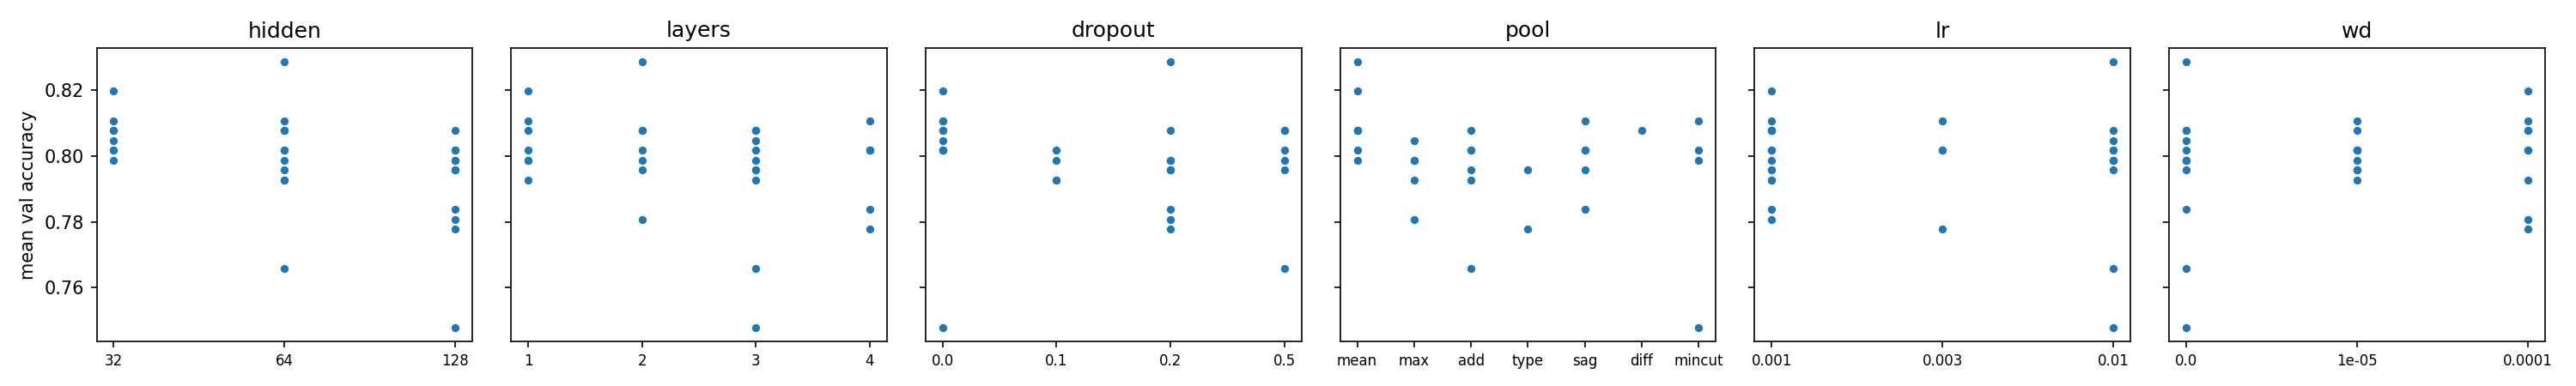

In [14]:
import matplotlib.pyplot as plt
search = search.sort_values('val', ascending=False)
print(search.head(10).round(4).to_string())
best = dict(trials[search.index[0]], norm=True, res=True, ffn=True, pe=True)
print("\nbest:", best)
fig, ax = plt.subplots(1, len(space), figsize=(20, 3), sharey=True)
for a, k in zip(ax, space):
    a.scatter(search[k].map(space[k].index), search.val, s=12)
    a.set_xticks(range(len(space[k])), [str(v) for v in space[k]], fontsize=8)
    a.set_title(k)
ax[0].set_ylabel("mean val accuracy")
plt.tight_layout(); plt.savefig('ginp_search.png', dpi=150); plt.show()

## 15. Test the tuned GIN⁺ on ten fresh seeds

The search used other seeds. We retrain the chosen configuration on the ten final seeds and score each run once on the 112 test proteins.

In [15]:
runs = [fit(best, s) for s in final_seeds]
P = np.stack([predict(m, test_b) for m, _ in runs])
tuned = pd.DataFrame([scores(y_test, p) for p in P])
print(pd.DataFrame({'plain': base.mean(), 'plain std': base.std(), 'tuned': tuned.mean(), 'tuned std': tuned.std()}).round(4))

      plain  plain std   tuned  tuned std
acc  0.7321     0.0282  0.7607     0.0252
f1   0.7028     0.0310  0.7441     0.0275
auc  0.7220     0.0603  0.8020     0.0252


## 16. The model we analyse

Analyses that need a single model use the run with the highest validation accuracy among the ten; picking the highest test accuracy would be peeking at the test set. Its confusion matrix shows whether the errors fall mostly on one class.

seed 109   val acc = 0.8378   test: {'acc': 0.7857, 'f1': 0.7667, 'auc': 0.8219}
trainable parameters: 55396


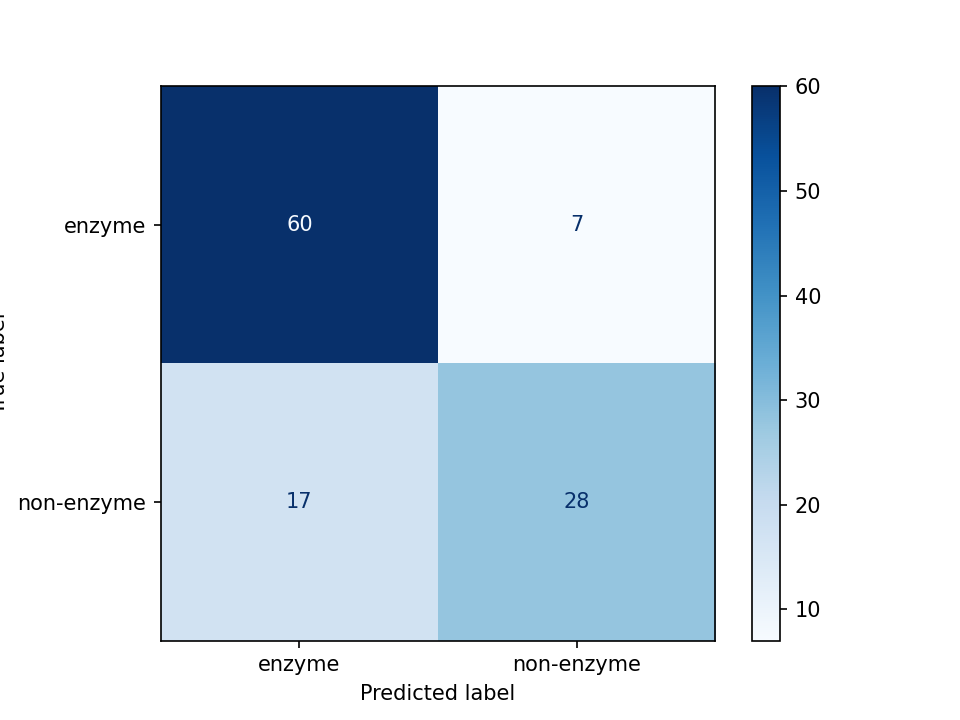

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
k = int(np.argmax([v for _, v in runs]))
model, p_best = runs[k][0], P[k]
print("seed", final_seeds[k], "  val acc =", round(runs[k][1], 4), "  test:", {m: round(float(v), 4) for m, v in scores(y_test, p_best).items()})
print("trainable parameters:", sum(p.numel() for p in model.parameters()))
ConfusionMatrixDisplay(confusion_matrix(y_test, p_best > .5), display_labels=['enzyme', 'non-enzyme']).plot(cmap='Blues')
plt.savefig('ginp_confusion.png', dpi=150); plt.show()

## 17. Permutation invariance, checked

A graph has no natural node order, so the prediction must not change when the SSEs are stored in a different order: $\mathrm{READOUT}(\mathbf{P}\mathbf{H})=\mathrm{READOUT}(\mathbf{H})$ for every permutation matrix $\mathbf{P}$. We shuffle the nodes of every test protein, relabel the edges, and compare the predictions. Floating-point sums in a different order give differences of about $10^{-6}$. With SAGPool one more effect can appear: the top-k cut is a hard threshold, so when two nodes' scores differ by less than that rounding error, the shuffle can swap which of them is kept and the probability moves by more than $10^{-6}$. That is a property of hard top-k selection, not a bug; a bug would flip many predictions.

In [17]:
def shuffle_nodes(g, seed):
    gen = torch.Generator().manual_seed(seed)
    perm = torch.randperm(g.num_nodes, generator=gen)
    inv = torch.empty_like(perm); inv[perm] = torch.arange(g.num_nodes)
    h = g.clone()
    h.x, h.pe, h.edge_index = g.x[perm], g.pe[perm], inv[g.edge_index]
    return h

p_shuf = predict(model, batches([shuffle_nodes(g, i) for i, g in enumerate(test_set)]))
print("largest change in P(non-enzyme) after shuffling:", float(np.abs(p_shuf - p_best).max()))
print("predictions that flip:", int(((p_shuf > .5) != (p_best > .5)).sum()), "of", len(p_best))

largest change in P(non-enzyme) after shuffling: 8.940696716308594e-08
predictions that flip: 0 of 112


## 18. Ablation: which tricks matter on PROTEINS?

This mirrors the ablation tables of Luo et al. We keep the tuned hyperparameters, switch off **one** trick at a time, and retrain on `abl_seeds`: no normalization, no dropout, no residual connections, no FFN, no positional encoding, and finally all tricks off (the plain GIN with the tuned width, depth and readout). `Δ acc` is the change against the full GIN⁺ on the same seeds.

                           acc      f1     auc  acc std   Δ acc
full GIN⁺               0.7607  0.7449  0.7942   0.0336  0.0000
no normalization        0.7839  0.7650  0.8352   0.0194  0.0232
no dropout              0.7321  0.7128  0.7799   0.0253 -0.0286
no residual             0.7518  0.7316  0.7920   0.0075 -0.0089
no FFN                  0.7768  0.7614  0.8400   0.0219  0.0161
no positional encoding  0.7518  0.7354  0.7824   0.0359 -0.0089
all tricks off          0.7554  0.7319  0.7599   0.0287 -0.0054


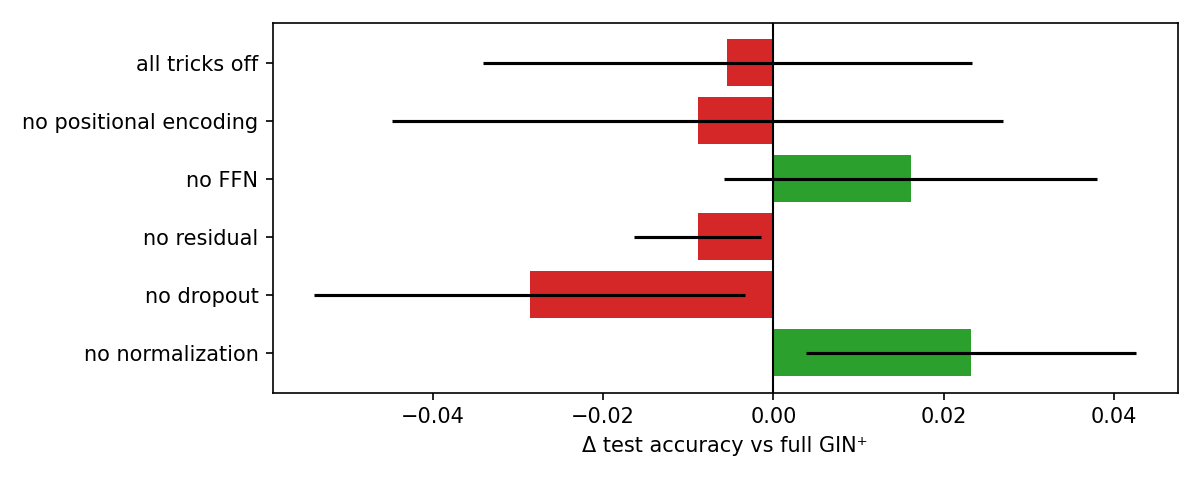

In [18]:
def run(c, seeds=abl_seeds, tr=None, va=None, te=None):
    te = te or test_b
    return pd.DataFrame([scores(y_test, predict(fit(c, s, tr, va)[0], te)) for s in seeds])

def table(d):
    t = pd.DataFrame({k: v.mean() for k, v in d.items()}).T
    t['acc std'] = [v.acc.std() for v in d.values()]
    t['Δ acc'] = t.acc - t.acc.iloc[0]
    return t.round(4)

def bars(t, ref, fname):
    d = t.iloc[1:]
    plt.figure(figsize=(8, 0.5 + 0.45 * len(d)))
    plt.barh(d.index, d['Δ acc'], xerr=d['acc std'], color=['tab:red' if v < 0 else 'tab:green' for v in d['Δ acc']])
    plt.axvline(0, color='k', lw=1); plt.xlabel(f"Δ test accuracy vs {ref}")
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

abl = {'full GIN⁺': tuned.iloc[:len(abl_seeds)]}
for name, change in [('no normalization', dict(norm=False)), ('no dropout', dict(dropout=0.0)),
                     ('no residual', dict(res=False)), ('no FFN', dict(ffn=False)),
                     ('no positional encoding', dict(pe=False)),
                     ('all tricks off', dict(norm=False, res=False, ffn=False, pe=False))]:
    if name == 'no dropout' and best['dropout'] == 0:
        continue
    abl[name] = run(dict(best, **change))
abl_t = table(abl)
print(abl_t)
bars(abl_t, 'full GIN⁺', 'ginp_ablation.png')

## 19. Ablation: does the model need the edges and the features?

Now the architecture stays tuned and we damage the **input**, in train, validation and test alike (Milestone 3 brief, *Ablation studies*):

- **No edges** ($\mathbf{A}=\mathbf{I}$): each node sees only itself, so message passing becomes a per-node MLP. If accuracy holds, the 3D contacts are not being used.
- **Constant features**: every $\mathbf{x}_v$ becomes a vector of ones, so only the shape of the protein is left. The type-aware readout then puts every node in the same slot.
- **SSE type only**: the length attribute is set to zero, so a node knows only whether it is a helix, a sheet or a turn.

The positional encodings are recomputed on the damaged graphs, so they cannot leak the structure back in.

In [19]:
def no_edges(g):
    h = g.clone(); h.edge_index = g.edge_index[:, :0]; h.pe = torch.zeros_like(g.pe); return h
def const_x(g):
    h = g.clone(); h.x = torch.ones_like(g.x); h.x[:, 2:] = 0; return h
def type_only(g):
    h = g.clone(); h.x = g.x.clone(); h.x[:, 0] = 0; return h

inp = {'tuned': tuned.iloc[:len(abl_seeds)]}
for name, f in [('no edges (A = I)', no_edges), ('constant features', const_x), ('SSE type only', type_only)]:
    tr, va, te = [[f(g) for g in d] for d in [train_set, val_set, test_set]]
    inp[name] = run(best, tr=tr, va=batches(va), te=batches(te))
inp_t = table(inp)
print(inp_t)

                      acc      f1     auc  acc std   Δ acc
tuned              0.7607  0.7449  0.7942   0.0336  0.0000
no edges (A = I)   0.7161  0.6930  0.8141   0.0263 -0.0446
constant features  0.7179  0.6920  0.7845   0.0080 -0.0429
SSE type only      0.7571  0.7319  0.8084   0.0172 -0.0036


## 20. Which readout suits PROTEINS?

Now only the readout changes and everything else stays tuned; `Δ acc` is measured against the tuned readout. The lecture's argument for hierarchical pooling is that one-shot sum, mean or max *forgets how nodes are organised*. A protein is organised into domains, so this is the dataset where DiffPool and MinCutPool have the best chance to help; on UPFD's star-shaped cascades they had little to find. Ying et al. reported DiffPool on PROTEINS, but Errica et al. (ICLR 2020) found that under a fair protocol it did not beat simple baselines there.

           acc      f1     auc  acc std   Δ acc
mean    0.7607  0.7449  0.7942   0.0336  0.0000
max     0.7732  0.7651  0.8409   0.0185  0.0125
add     0.7643  0.7442  0.8269   0.0162  0.0036
type    0.7179  0.7056  0.7765   0.0343 -0.0429
sag     0.7821  0.7684  0.8416   0.0174  0.0214
diff    0.7679  0.7501  0.8198   0.0109  0.0071
mincut  0.7304  0.7109  0.8023   0.0147 -0.0304


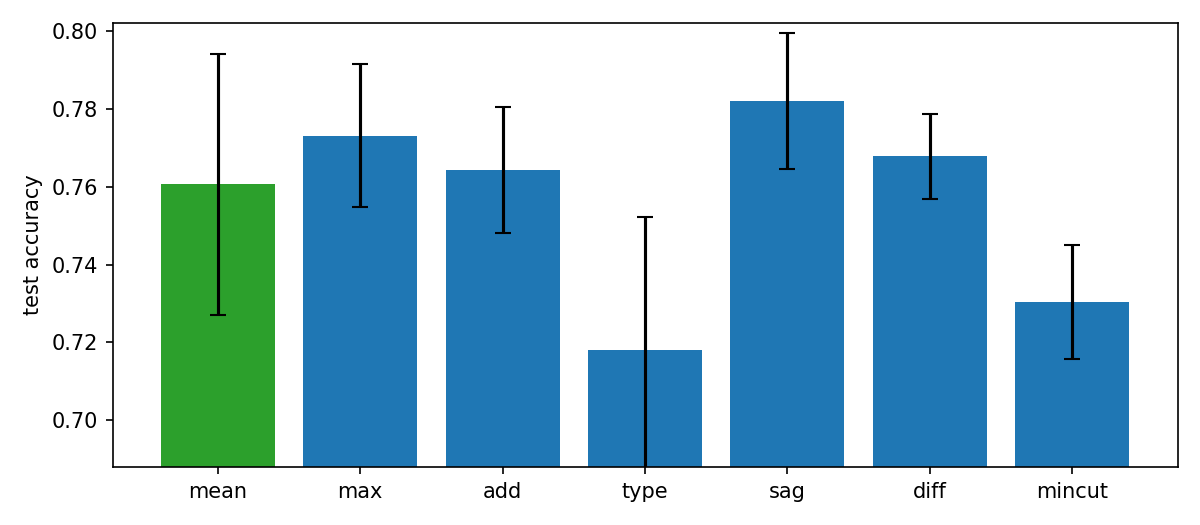

In [20]:
pool_res = {}
for p in [best['pool']] + [q for q in space['pool'] if q != best['pool']]:
    pool_res[p] = tuned.iloc[:len(abl_seeds)] if p == best['pool'] else run(dict(best, pool=p))
pool_t = table(pool_res)
print(pool_t)
plt.figure(figsize=(8, 3.5))
plt.bar(pool_t.index, pool_t.acc, yerr=pool_t['acc std'], capsize=4,
        color=['tab:green' if p == best['pool'] else 'tab:blue' for p in pool_t.index])
plt.ylim(pool_t.acc.min() - 0.03, min(1, pool_t.acc.max() + 0.02)); plt.ylabel("test accuracy")
plt.tight_layout(); plt.savefig('ginp_readout.png', dpi=150); plt.show()

## 21. Depth with and without residual connections

Lecture 17, *Finding 3*: deep stacks without residuals collapse through over-smoothing, because repeated neighbourhood aggregation pulls every node of a graph towards the same embedding. A protein graph is a long chain with short-cuts, so it takes more hops than a cascade to cover the whole graph. We train 2, 4, 8 and 16 layers with and without residuals on `sweep_seeds`.

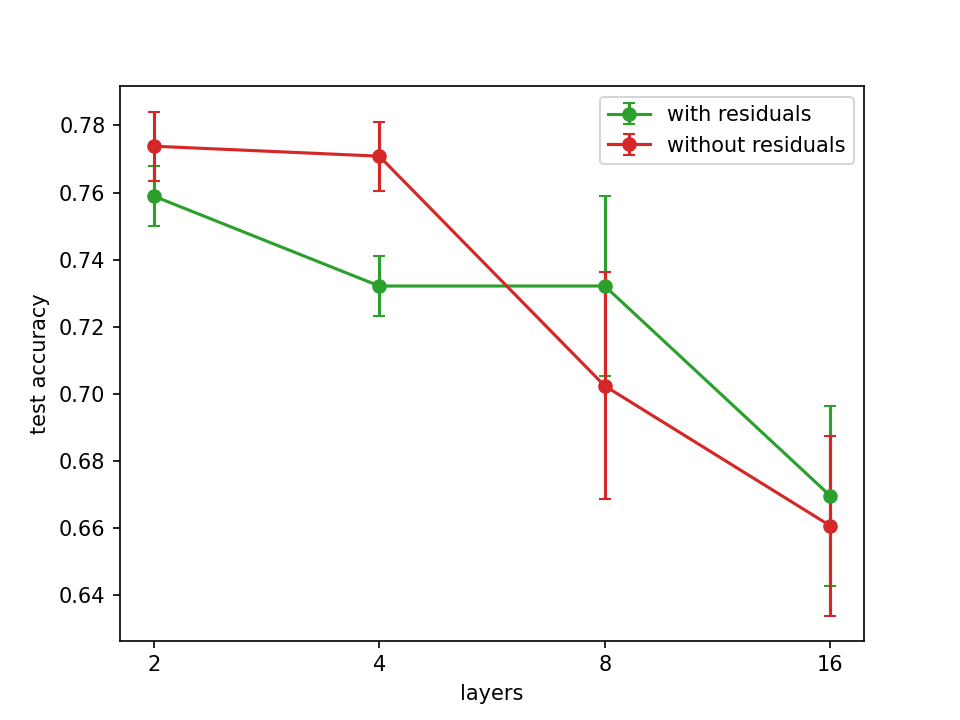

In [21]:
Ls = [2, 4, 8, 16]
depth = {(r, L): run(dict(best, res=r, layers=L), sweep_seeds) for r in [True, False] for L in Ls}
for r, col in [(True, 'tab:green'), (False, 'tab:red')]:
    plt.errorbar(Ls, [depth[r, L].acc.mean() for L in Ls], [depth[r, L].acc.std() for L in Ls],
                 marker='o', capsize=3, color=col, label='with residuals' if r else 'without residuals')
plt.xscale('log', base=2); plt.xticks(Ls, Ls); plt.xlabel("layers"); plt.ylabel("test accuracy"); plt.legend()
plt.savefig('ginp_depth.png', dpi=150); plt.show()

## 22. Dropout sensitivity

Lecture 17, *Finding 4*: dropout inside message passing distorts every aggregated message, and on the benchmarks of Luo et al. the best rates were mostly 0.2 or lower. We sweep the rate on `sweep_seeds` with everything else tuned.

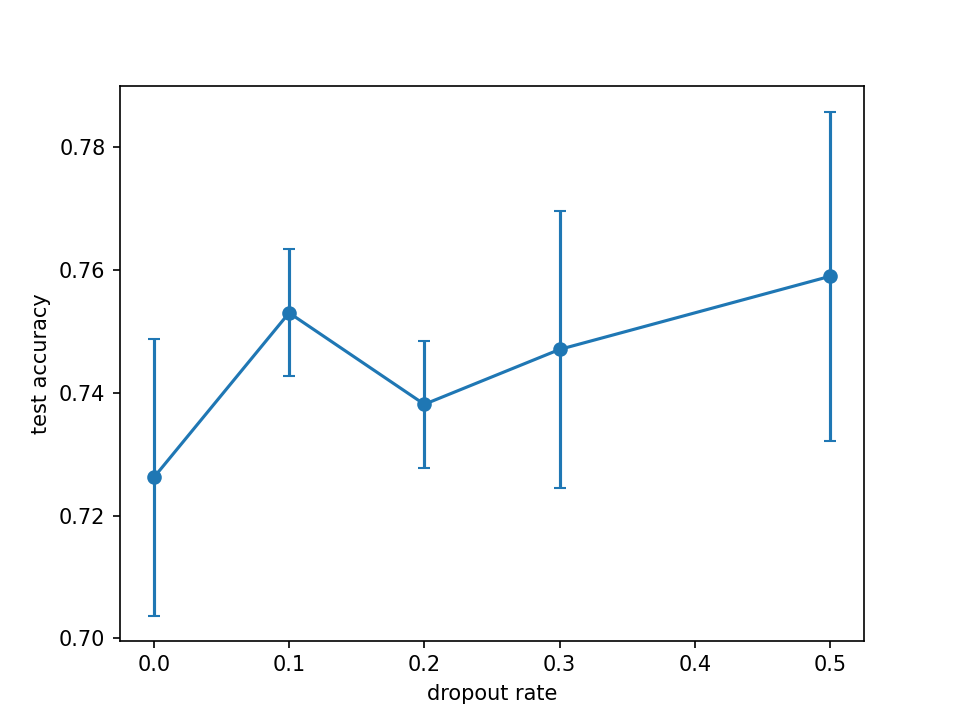

In [22]:
rates = [0.0, 0.1, 0.2, 0.3, 0.5]
drop = {p: run(dict(best, dropout=p), sweep_seeds) for p in rates}
plt.errorbar(rates, [drop[p].acc.mean() for p in rates], [drop[p].acc.std() for p in rates], marker='o', capsize=3)
plt.xlabel("dropout rate"); plt.ylabel("test accuracy")
plt.savefig('ginp_dropout.png', dpi=150); plt.show()

## 23. Visualisation: t-SNE of graph embeddings

`embed` returns the vector the classifier sees, one per protein. t-SNE maps these vectors to 2D while keeping near neighbours near. On the left is the mean of each protein's raw node features, on the right the tuned GIN⁺ embedding. Colour is the true class, and crosses are proteins the model gets wrong: if they sit on the border between the two clouds, the model fails on genuinely ambiguous cases. The silhouette score, computed in the original space, measures class separation from $-1$ to $1$.

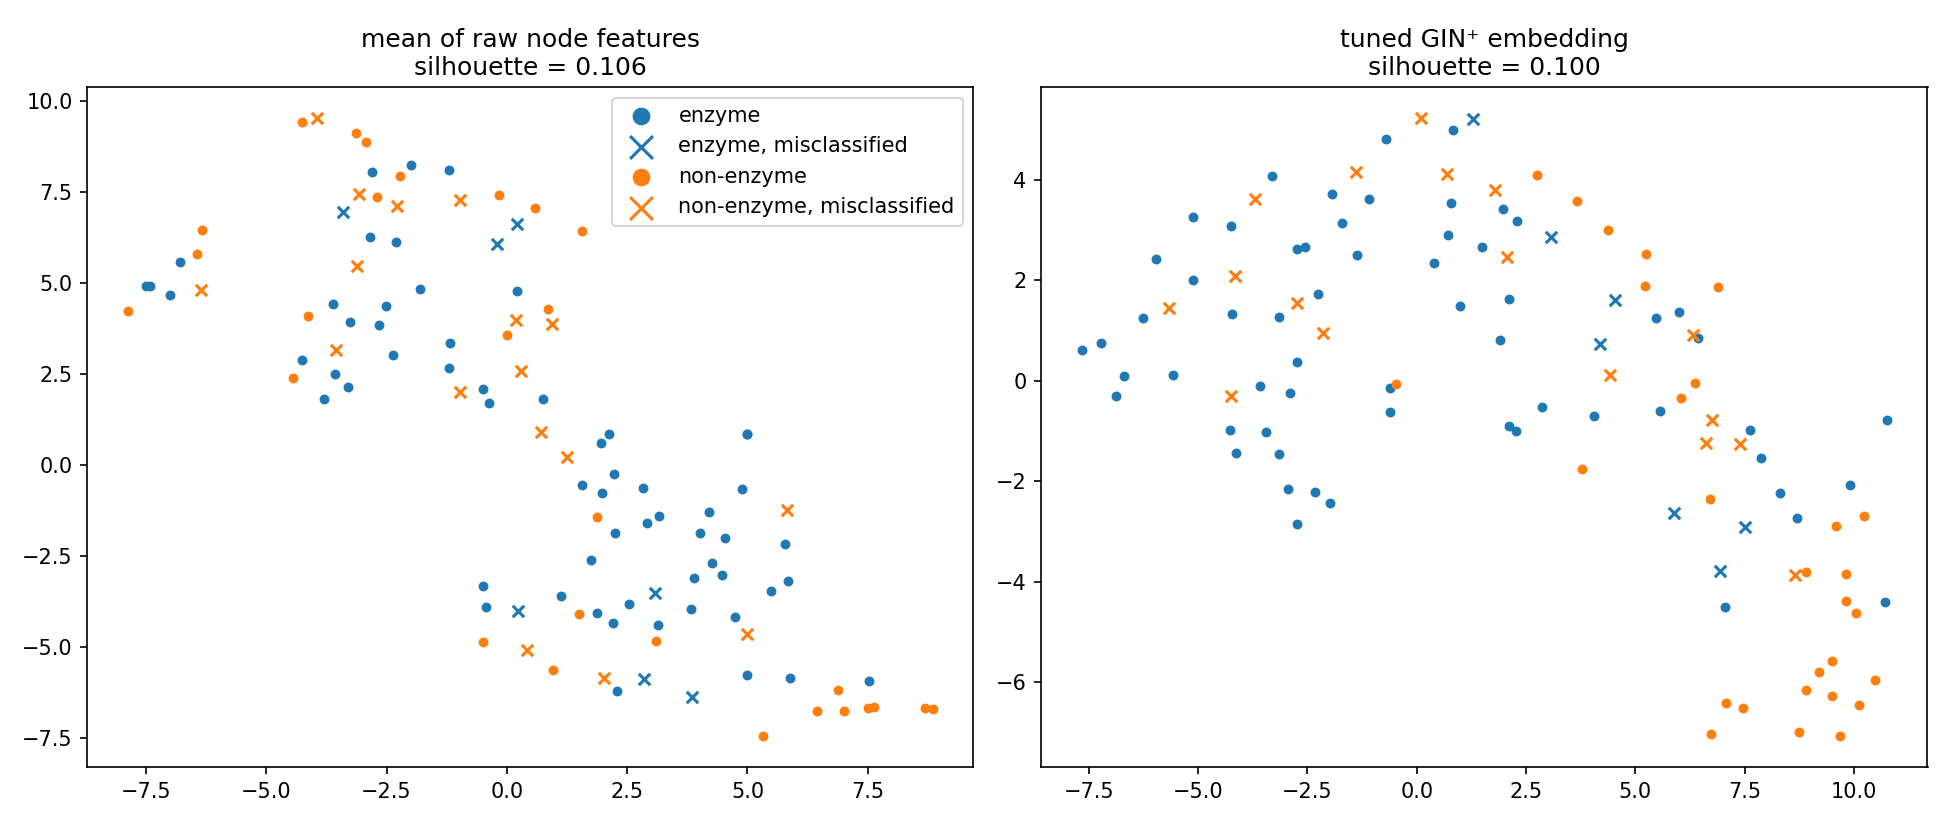

In [23]:
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

@torch.no_grad()
def embed_all(model, bs):
    model.eval()
    return torch.cat([model.embed(b.x, b.edge_index, b.pe, b.batch) for b in bs]).cpu().numpy()

Z = {'mean of raw node features': torch.cat([global_mean_pool(b.x, b.batch) for b in test_b]).cpu().numpy(),
     'tuned GIN⁺ embedding': embed_all(model, test_b)}
sil = {name: silhouette_score(E, y_test) for name, E in Z.items()}
wrong = (p_best > .5) != y_test
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, (name, E) in zip(ax, Z.items()):
    T2 = TSNE(2, init='pca', random_state=0, perplexity=min(30, len(E) // 4)).fit_transform(E)
    for c, col, lab in [(0, 'tab:blue', 'enzyme'), (1, 'tab:orange', 'non-enzyme')]:
        a.scatter(*T2[(y_test == c) & ~wrong].T, s=14, c=col, label=lab)
        a.scatter(*T2[(y_test == c) & wrong].T, s=30, c=col, marker='x', label=f'{lab}, misclassified')
    a.set_title(f"{name}\nsilhouette = {sil[name]:.3f}")
ax[0].legend(markerscale=2)
plt.tight_layout(); plt.savefig('ginp_tsne.png', dpi=150); plt.show()

## 24. Efficiency: what does each readout cost?

Milestone 3 asks for the computational cost of accuracy. For the tuned model and for each readout we measure the number of trainable parameters, the training time per epoch, the time to predict all 112 test proteins, and the peak GPU memory during one epoch. Dense DiffPool and MinCutPool build an $n_{\max}\times n_{\max}$ adjacency for every graph in the batch, so they should be the most expensive. Each number is the median of three epochs after one warm-up epoch.

In [24]:
def cost(c):
    seed_everything(0)
    m = Net(**c).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=c['lr'])
    loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    times = []
    if device == 'cuda':
        torch.cuda.reset_peak_memory_stats()
    for e in range(4):
        if device == 'cuda': torch.cuda.synchronize()
        t = time.time(); m.train()
        for b in loader:
            b = b.to(device); opt.zero_grad()
            (F.cross_entropy(m(b.x, b.edge_index, b.pe, b.batch), b.y) + m.aux).backward(); opt.step()
        if device == 'cuda': torch.cuda.synchronize()
        times.append(time.time() - t)
    t = time.time(); predict(m, test_b)
    if device == 'cuda': torch.cuda.synchronize()
    return dict(params=sum(p.numel() for p in m.parameters()), s_per_epoch=float(np.median(times[1:])),
                infer_s=time.time() - t, peak_mb=torch.cuda.max_memory_allocated() / 2**20 if device == 'cuda' else float('nan'))

eff = pd.DataFrame({p: cost(dict(best, pool=p)) for p in space['pool']}).T
eff['test acc'] = pool_t.acc.reindex(eff.index)
print(eff.round(4))

         params  s_per_epoch  infer_s   peak_mb  test acc
mean    55396.0       0.1347   0.0026   46.9302    0.7607
max     55396.0       0.1290   0.0027   49.1206    0.7732
add     55396.0       0.1350   0.0027   46.9302    0.7643
type    63588.0       0.1521   0.0035   49.0747    0.7179
sag     59557.0       0.1687   0.0045   51.0498    0.7821
diff    60206.0       0.2006   0.0058  435.6924    0.7679
mincut  64302.0       0.2248   0.0060  261.1479    0.7304


## 25. Robustness: missing edges and noisy features

Protein contact graphs come from structures that can be incomplete or noisy. Without retraining, we damage only the **test** proteins and measure how fast accuracy falls (Milestone 3 brief, *Robustness*):

- **Edge removal**: drop a fraction of the edges, both directions together, at random; positional encodings are recomputed on the damaged graph.
- **Feature noise**: add Gaussian noise $\mathcal{N}(0,\sigma^2)$ to every node feature, both the scaled length and the one-hot type. The length is standardised, so $\sigma=0.5$ is half its spread across proteins.

Each point is the mean over three random damages.

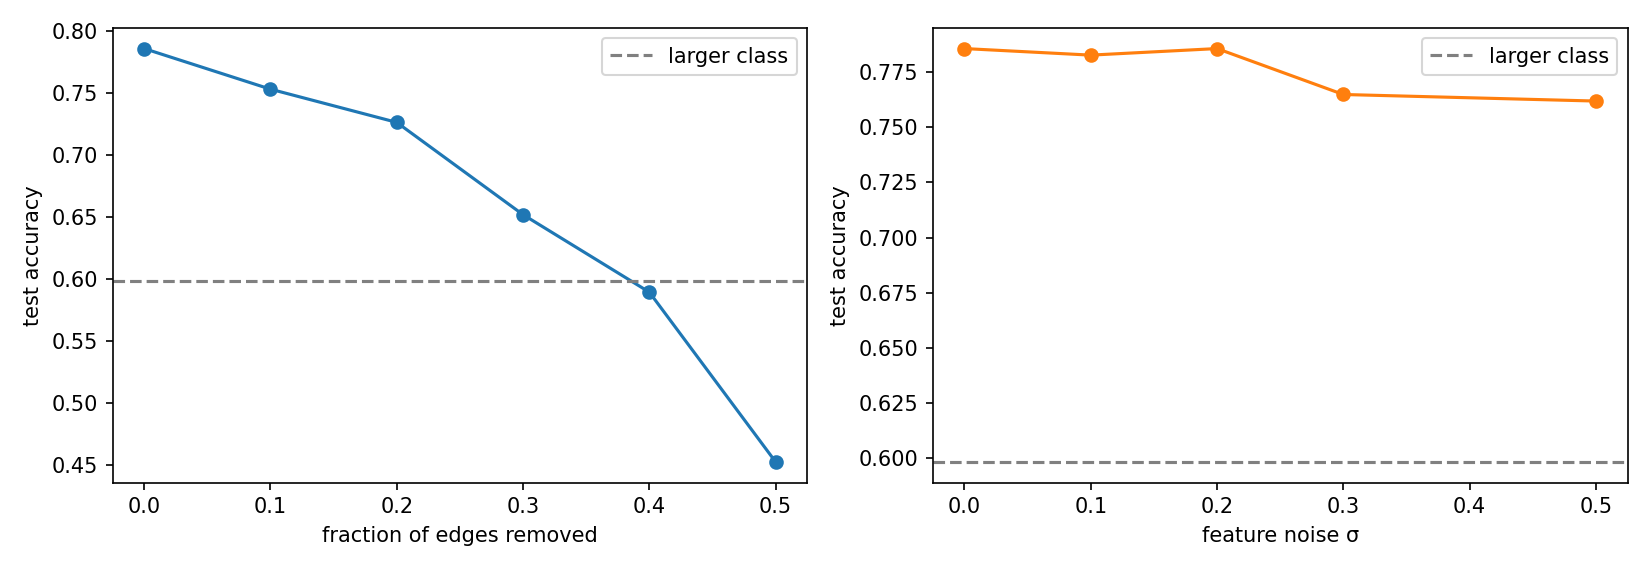

In [25]:
from torch_geometric.utils import dropout_edge

def drop_edges(g, p, seed):
    torch.manual_seed(seed)
    h = g.clone(); h.edge_index, _ = dropout_edge(g.edge_index, p=p, force_undirected=True)
    h.pe = rw(h).pe; return h
def noisy(g, s, seed):
    torch.manual_seed(seed)
    h = g.clone(); h.x = g.x + s * torch.randn_like(g.x); return h

edge_ps, sigmas = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5], [0.0, 0.1, 0.2, 0.3, 0.5]
rob_edge = {p: np.mean([accuracy_score(y_test, predict(model, batches([drop_edges(g, p, r) for g in test_set])) > .5) for r in range(3)]) for p in edge_ps}
rob_noise = {s: np.mean([accuracy_score(y_test, predict(model, batches([noisy(g, s, r) for g in test_set])) > .5) for r in range(3)]) for s in sigmas}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(edge_ps, list(rob_edge.values()), marker='o'); ax[0].set_xlabel("fraction of edges removed")
ax[1].plot(sigmas, list(rob_noise.values()), marker='o', color='tab:orange'); ax[1].set_xlabel("feature noise σ")
for a in ax:
    a.axhline(majority, ls='--', c='grey', label='larger class'); a.set_ylabel("test accuracy"); a.legend()
plt.tight_layout(); plt.savefig('ginp_robustness.png', dpi=150); plt.show()

## 26. Error analysis by graph shape

The brief's examples are node-level (accuracy by node degree); for graph classification the natural unit is the protein. We describe every test protein by three structural properties and group the test accuracy by tertile of each (there are only 112 test proteins):

- **size** $|V|$, the number of SSEs;
- **average degree**, how many contacts an SSE has, i.e. how compactly the protein folds;
- **clustering coefficient**, how often two contacts of an SSE are also in contact, a measure of tightly packed motifs.

A model that leans on the structure should be most accurate on proteins whose shape is typical of their class.


size
                  acc   n  enzyme
size                            
(4.999, 19.0]  0.737  38   0.316
(19.0, 40.0]   0.694  36   0.611
(40.0, 226.0]  0.921  38   0.868

degree
                   acc   n  enzyme
degree                           
(2.374, 3.6]    0.805  41   0.488
(3.6, 3.921]    0.794  34   0.647
(3.921, 4.698]  0.757  37   0.676

clustering
                                  acc   n  enzyme
clustering                                      
(0.018099999999999998, 0.395]  0.811  37   0.649
(0.395, 0.632]                 0.737  38   0.711
(0.632, 0.9]                   0.811  37   0.432


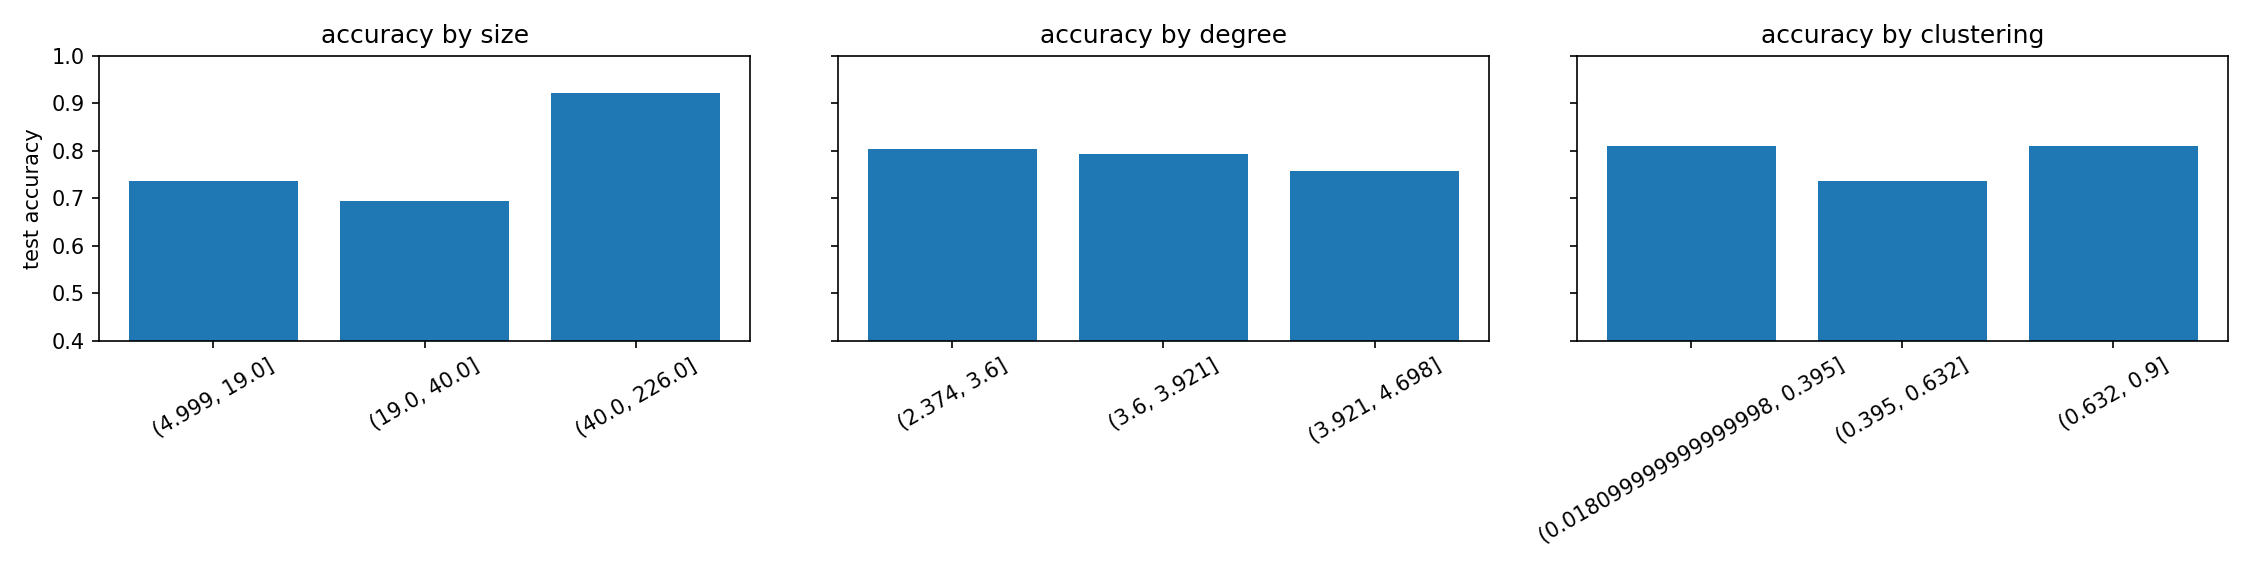

In [26]:
import networkx as nx
from torch_geometric.utils import to_networkx

def shape(g):
    G = to_networkx(g, to_undirected=True)
    return dict(size=g.num_nodes, degree=g.num_edges / g.num_nodes, clustering=nx.average_clustering(G))

shp = pd.DataFrame([shape(g) for g in test_set])
shp['correct'] = (p_best > .5) == y_test
shp['enzyme'] = 1 - y_test
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
topo = {}
for a, col in zip(ax, ['size', 'degree', 'clustering']):
    q = pd.qcut(shp[col], 3, duplicates='drop')
    t = shp.groupby(q, observed=True).agg(acc=('correct', 'mean'), n=('correct', 'size'), enzyme=('enzyme', 'mean'))
    topo[col] = t.reset_index().astype(str).to_dict('records')
    print(f"\n{col}\n", t.round(3))
    a.bar([str(i) for i in t.index], t.acc, color='tab:blue'); a.set_title(f"accuracy by {col}")
    a.tick_params(axis='x', rotation=30); a.set_ylim(0.4, 1)
ax[0].set_ylabel("test accuracy")
plt.tight_layout(); plt.savefig('ginp_topology.png', dpi=150); plt.show()

## 27. Explainability: which SSEs drive the prediction?

We ask **GNNExplainer** (Ying et al., NeurIPS 2019) which nodes of a protein the tuned model relies on. For one graph it learns a soft mask over the nodes that keeps the prediction while using as few nodes as possible, and returns an importance score per node.

A mask is only useful if it is faithful. We measure **fidelity** by deletion: remove the top 10% most important SSEs and record how much the predicted probability of the predicted class drops. If the explainer is right, this drop should be much larger than when we remove the same number of *random* SSEs. We do this on up to 100 test proteins with at least 20 nodes. We also count which SSE types the explainer ranks highest, against how common each type is.

GNNExplainer writes its mask into the message-passing layers of the model it explains, which corrupts that model for later use, so we explain a copy.

In [27]:
from torch_geometric.explain import Explainer, GNNExplainer
from torch_geometric.utils import subgraph

expl = Explainer(model=copy.deepcopy(model), algorithm=GNNExplainer(epochs=100),
                 explanation_type='model', node_mask_type='object', edge_mask_type=None,
                 model_config=dict(mode='multiclass_classification', task_level='graph', return_type='raw'))

@torch.no_grad()
def prob(g):
    model.eval(); g = g.clone().to(device)  # Data.to() moves in place; keep the caller's graph on the CPU
    return model(g.x, g.edge_index, g.pe, g.edge_index.new_zeros(g.num_nodes)).softmax(1)[0].cpu()

def delete(g, drop):
    keep = torch.ones(g.num_nodes, dtype=torch.bool); keep[drop] = False
    ei, _ = subgraph(keep, g.edge_index, relabel_nodes=True, num_nodes=g.num_nodes)
    h = g.clone(); h.x, h.edge_index = g.x[keep], ei; h.pe = rw(h).pe; return h

rng = np.random.default_rng(0)
cand = [i for i, g in enumerate(test_set) if g.num_nodes >= 20]
picked = rng.choice(cand, size=min(100, len(cand)), replace=False)
fid, masks, top_types = [], {}, []
for i in picked:
    g = test_set[i].clone().to(device)
    m_ = expl(g.x, g.edge_index, pe=g.pe, batch=g.edge_index.new_zeros(g.num_nodes)).node_mask.flatten().cpu()
    masks[int(i)] = m_
    g = g.cpu(); p0 = prob(g); c = int(p0.argmax()); kk = max(1, int(0.1 * g.num_nodes))
    order = torch.argsort(m_, descending=True)
    rand = torch.from_numpy(rng.permutation(g.num_nodes))
    top_types += g.x[order[:kk], 1:4].argmax(1).tolist()
    fid.append(dict(top=float(p0[c] - prob(delete(g, order[:kk]))[c]), random=float(p0[c] - prob(delete(g, rand[:kk]))[c])))
fid = pd.DataFrame(fid)
print("mean drop in confidence, top-10% SSEs removed:   ", round(fid.top.mean(), 4))
print("mean drop in confidence, random 10% SSEs removed:", round(fid.random.mean(), 4))
names = ['helix', 'sheet', 'turn']
share_all = torch.cat([test_set[i].x[:, 1:4] for i in picked]).mean(0).numpy()
share_top = np.bincount(top_types, minlength=3) / len(top_types)
type_share = pd.DataFrame({'all nodes': share_all, 'top-10% nodes': share_top}, index=names)
print(type_share.round(3))

mean drop in confidence, top-10% SSEs removed:    0.1016
mean drop in confidence, random 10% SSEs removed: 0.0568
       all nodes  top-10% nodes
helix      0.467          0.589
sheet      0.486          0.357
turn       0.047          0.054


## 28. Explained proteins

We draw three explained proteins, one correctly classified enzyme, one correctly classified non-enzyme, and one error. Node colour shows GNNExplainer's importance and node shape the SSE type (circle helix, square sheet, triangle turn). A useful explanation would point at a compact group of SSEs, such as an active-site pocket, rather than spread its importance evenly.

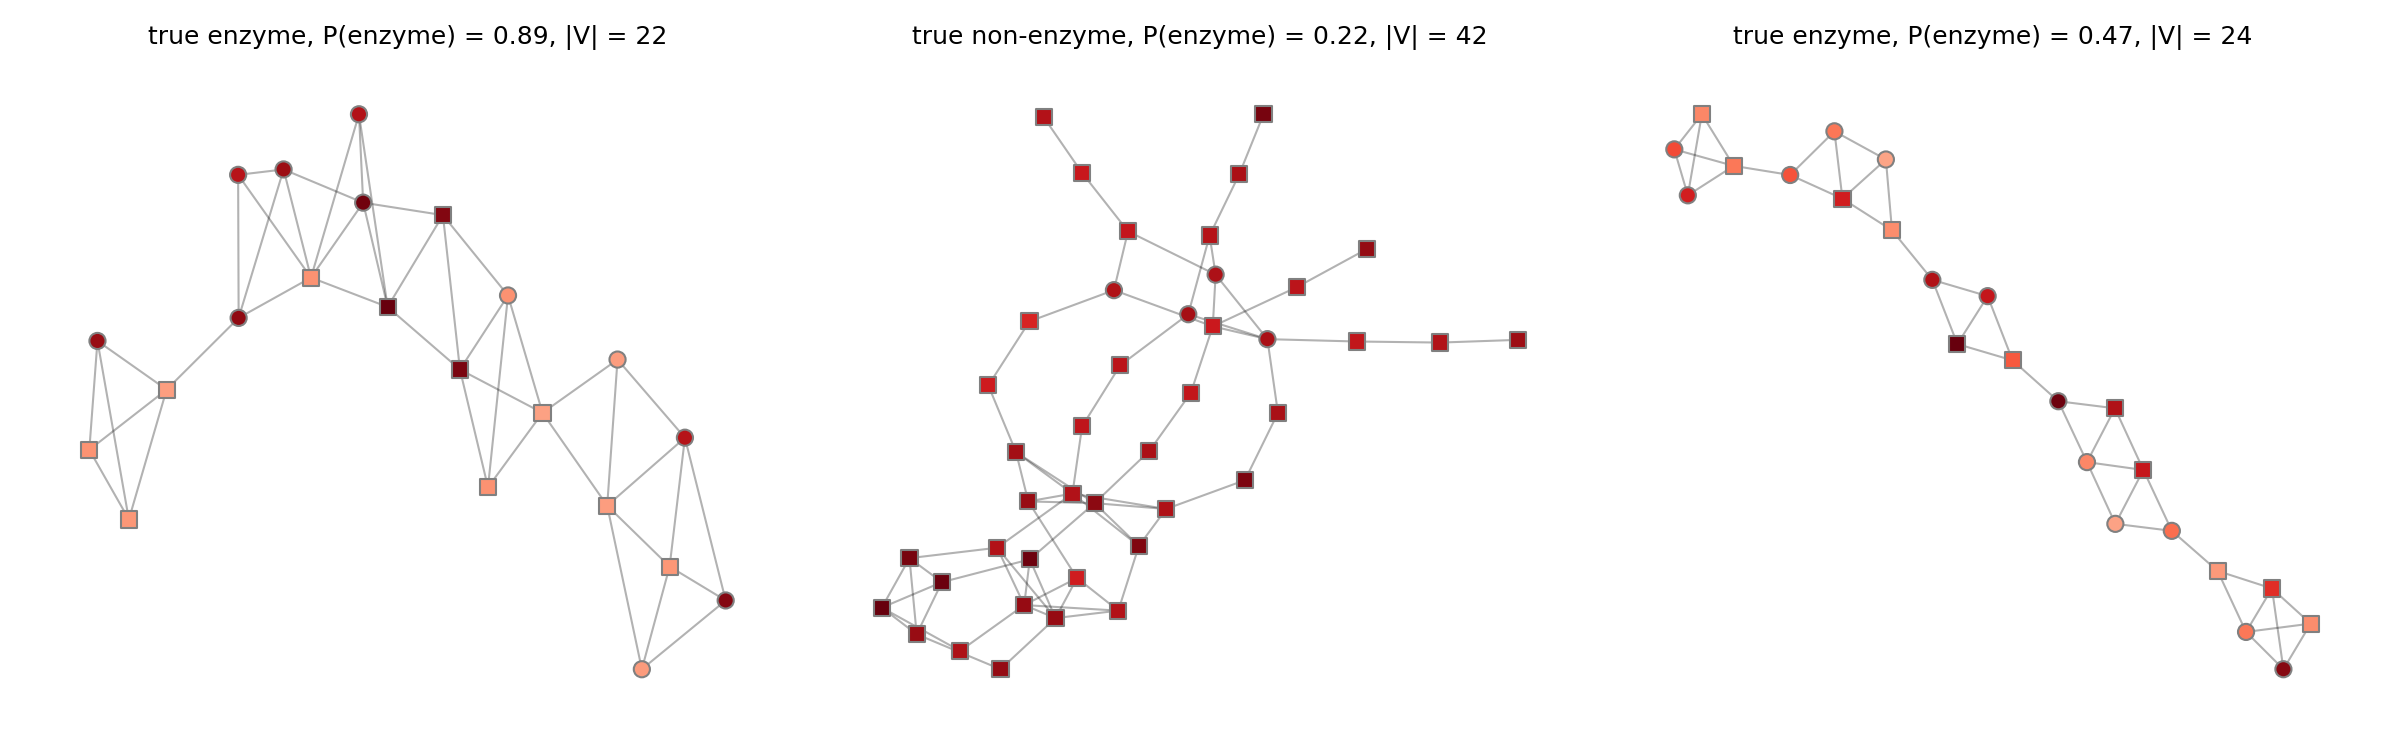

In [28]:
def pick(cond):
    for i in masks:
        if cond(i): return i
chosen = [pick(lambda i: y_test[i] == 0 and p_best[i] <= .5), pick(lambda i: y_test[i] == 1 and p_best[i] > .5),
          pick(lambda i: (p_best[i] > .5) != y_test[i])]
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for a, i in zip(ax, chosen):
    if i is None: a.axis('off'); continue
    g = test_set[i]; G = to_networkx(g, to_undirected=True); pos = nx.kamada_kawai_layout(G); w = masks[i].numpy()
    kind = g.x[:, 1:4].argmax(1).numpy()
    nx.draw_networkx_edges(G, pos, ax=a, alpha=.3)
    for t, shp_ in zip(range(3), 'os^'):
        nl = [v for v in range(len(w)) if kind[v] == t]
        nx.draw_networkx_nodes(G, pos, nodelist=nl, node_color=w[nl], cmap='Reds', vmin=0, vmax=w.max(), node_shape=shp_, node_size=60, edgecolors='grey', ax=a)
    a.set_title(f"true {'non-enzyme' if y_test[i] else 'enzyme'}, P(enzyme) = {1 - p_best[i]:.2f}, |V| = {len(w)}"); a.axis('off')
plt.tight_layout(); plt.savefig('ginp_explained_proteins.png', dpi=150); plt.show()

## 29. Explainability: which feature matters?

Each node has two kinds of feature: its SSE type (3 one-hot numbers) and its length. We measure the drop in confidence when one of them is replaced by its training-set mean in every node (the brief's *drop in confidence when features are masked*).

In [29]:
mu = torch.cat([g.x for g in train_set]).mean(0)
def mask_cols(g, cols):
    h = g.clone(); h.x = g.x.clone(); h.x[:, cols] = mu[cols]; return h

p_c = np.where(p_best > .5, p_best, 1 - p_best)
feat = {}
for name, cols in [('SSE type (3)', slice(1, 4)), ('length (1)', slice(0, 1))]:
    p = predict(model, batches([mask_cols(g, cols) for g in test_set]))
    feat[name] = dict(conf_drop=float(np.mean(p_c - np.where(p_best > .5, p, 1 - p))), acc=accuracy_score(y_test, p > .5))
feat = pd.DataFrame(feat).T
print(feat.round(4))

              conf_drop     acc
SSE type (3)     0.0223  0.6964
length (1)       0.1432  0.6875


## 30. Save the results

Everything needed to compare this model with the others goes into one JSON file. The per-run test probabilities are saved too, so the errors of all models can later be compared graph by graph.

In [30]:
import json
res = dict(model='GIN⁺', dataset='PROTEINS', references=dict(majority=majority, size_only=size_acc, bag_of_nodes=bag_acc),
           split=dict(rule='stratified 80/10/10, random_state=0', train=train_idx.tolist(), val=val_idx.tolist(), test=test_idx.tolist()),
           best_config=best, plain=base.agg(['mean', 'std']).to_dict(), tuned=tuned.agg(['mean', 'std']).to_dict(),
           tuned_runs=tuned.to_dict('list'), params=sum(p.numel() for p in model.parameters()),
           permutation_max_change=float(np.abs(p_shuf - p_best).max()),
           ablation=abl_t.to_dict('index'), input_ablation=inp_t.to_dict('index'), readout=pool_t.to_dict('index'),
           depth={f'res={r}, layers={L}': [v.acc.mean(), v.acc.std()] for (r, L), v in depth.items()},
           dropout={str(p): [v.acc.mean(), v.acc.std()] for p, v in drop.items()},
           silhouette=sil, efficiency=eff.to_dict('index'),
           robustness=dict(edges={str(k): v for k, v in rob_edge.items()}, noise={str(k): v for k, v in rob_noise.items()}),
           topology=topo, fidelity=fid.mean().to_dict(), explainer_types=type_share.to_dict(), feature_masking=feat.to_dict('index'),
           minutes=(time.time() - t0) / 60)
json.dump(res, open('ginp_proteins_results.json', 'w'), indent=1, default=float)
np.save('ginp_proteins_test_probs.npy', P)
search.to_csv('ginp_proteins_search.csv', index=False)
print("saved:", ', '.join(sorted(res)))
print(f"total run time: {res['minutes']:.0f} minutes")

saved: ablation, best_config, dataset, depth, dropout, efficiency, explainer_types, feature_masking, fidelity, input_ablation, minutes, model, params, permutation_max_change, plain, readout, references, robustness, silhouette, split, topology, tuned, tuned_runs
total run time: 42 minutes


## 31. Conclusion

*To be written from the Kaggle run.*